# Vectorial diffraction: longitudinal fields, vector beams and high NA foci

The scalar propagators treat each Cartesian field component on its own.
That is fine as long as all plane waves of a beam travel almost along $z$.
For strongly diverging beams (small waists, high numerical apertures) it
misses something: an electromagnetic wave is transverse, $\mathbf{k}\cdot\mathbf{E} = 0$
for every plane wave, so tilted plane waves carry a longitudinal component
$E_z$. This notebook shows the vectorial tools of `pyoptics.propagators`:

| Function | What it does |
|---|---|
| `longitudinal_component(E_x, E_y, x, y, wl, n)` | $E_z$ from the transverse components via $\nabla\cdot\mathbf{E} = 0$: $\tilde E_z = -(k_x\tilde E_x + k_y\tilde E_y)/k_z$ |
| `vectorial_rayleigh_sommerfeld_TF(field, x, y, z, wl, n)` | exact angular spectrum propagation of a field $[E_x, E_y]$ given in a plane; returns $[E_x, E_y, E_z]$ |
| `propagate_vectorial(propagator, field, ...)` | any scalar propagator for $E_x, E_y$, plus $E_z$ (from $\nabla\cdot\mathbf{E}=0$, or $\mathbf{E}\cdot\mathbf{r} = 0$ for `fraunhofer()`) |
| `propagate_padded(...)` | also accepts vector fields of shape `(Ny, Nx, 2)` or `(Ny, Nx, 3)` |
| `vectorial_mansuripur(field, x, y, z, wl, n)` | Mansuripur's method for the focus of an aplanatic high NA lens (Richards-Wolf theory) |
| `aplanatic_rotation(sigma_x, sigma_y)` | the polarization rotation of a ray bent by an aplanatic lens |

Vector fields are arrays of shape `(Ny, Nx, 2)` with $[E_x, E_y]$ or
`(Ny, Nx, 3)` with $[E_x, E_y, E_z]$. Convention as everywhere in pyoptics:
fields vary as $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$. All lengths are
in units of the wavelength.

In [1]:
import functools

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import jv, j1

from pyoptics.fft import FT, inv_FT
from pyoptics.propagators import (longitudinal_component, vectorial_rayleigh_sommerfeld_TF,
                                  propagate_vectorial, propagate_padded, vectorial_mansuripur,
                                  aplanatic_rotation, rayleigh_sommerfeld_I_TF, fresnel_TF,
                                  fraunhofer)
from pyoptics.utils import grid1d, freq_grid

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 1.0
k = 2*np.pi/wl

def grid(L, N):
    x = grid1d(-L/2, L/2, N)
    return x, x, *np.meshgrid(x, x)

def components(E):
    return [np.abs(E[:, :, i])**2 for i in range(3)]

def show_components(E, x, y, title, extent_half=None, fig_title=None, total=True):
    """Plot |E_x|², |E_y|², |E_z|² (and the sum) normalized to the peak of the sum."""
    I = components(E)
    I_tot = sum(I)
    m = I_tot.max()
    panels = I + ([I_tot] if total else [])
    names = ["$|E_x|^2$", "$|E_y|^2$", "$|E_z|^2$", "$|\\mathbf{E}|^2$"]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.6*len(panels), 3.4))
    ext = [x[0], x[-1], y[0], y[-1]]
    for ax, img, name in zip(axes, panels, names):
        vmax = img.max()/m if img.max()/m > 1e-6 else 1.0   # identically zero: plain black panel
        im = ax.imshow(img/m, extent=ext, cmap="inferno", vmin=0, vmax=vmax)
        ax.set_title(f"{name}  (peak {img.max()/m:.3f})", fontsize=10)
        ax.set_xlabel("x [λ]")
        if extent_half:
            ax.set_xlim(-extent_half, extent_half); ax.set_ylim(-extent_half, extent_half)
        fig.colorbar(im, ax=ax, shrink=0.8)
    axes[0].set_ylabel("y [λ]")
    fig.suptitle(fig_title or title)
    fig.tight_layout()
    return fig

## 1. The longitudinal field of a tilted plane wave

A plane wave $\exp(i(k_x x + k_z z))$ that is polarized in the $x$-$z$ plane
has $E_z = -E_x k_x/k_z = -E_x\tan\theta$. `longitudinal_component()` finds this
from $E_x$ alone. The plane waves are chosen on the frequency grid of the
window, so the FFT represents them exactly.

max deviation from -tan(theta): 1.1577929790155044e-15


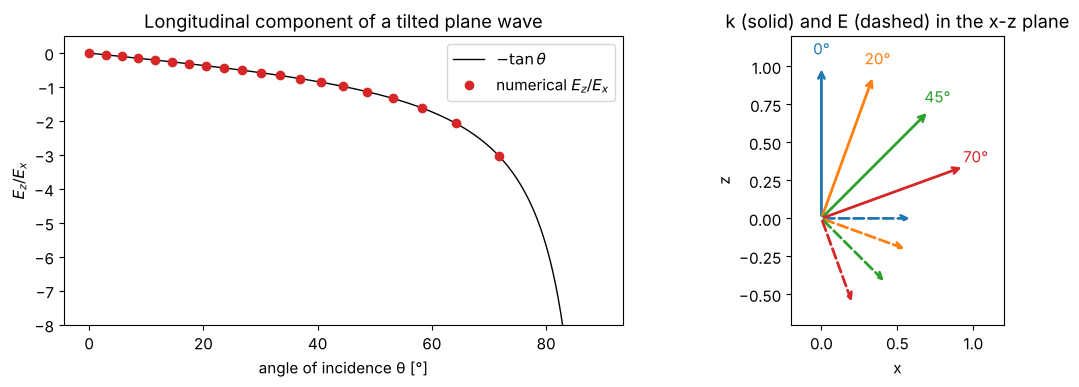

In [2]:
x, y, X, Y = grid(20.0, 128)
m_vals = np.arange(0, 20)
kx_vals = 2*np.pi*m_vals/20.0
theta = np.arcsin(kx_vals/k)
ratio = []
for kx in kx_vals:
    E_x = np.exp(1j*kx*X)
    E_z = longitudinal_component(E_x, 0*E_x, x, y, wl)
    ratio.append((E_z/E_x)[64, 64])
ratio = np.array(ratio)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
th = np.linspace(0, 89, 400)
axes[0].plot(th, -np.tan(np.radians(th)), "k-", lw=1, label="$-\\tan\\theta$")
axes[0].plot(np.degrees(theta), ratio.real, "o", color="C3", label="numerical $E_z/E_x$")
axes[0].set_ylim(-8, 0.5); axes[0].set_xlabel("angle of incidence θ [°]"); axes[0].set_ylabel("$E_z/E_x$")
axes[0].legend(); axes[0].set_title("Longitudinal component of a tilted plane wave")

# the field vector stays perpendicular to k: draw E and k in the x-z plane
for t, c in zip([0, 20, 45, 70], ["C0", "C1", "C2", "C3"]):
    tr = np.radians(t)
    kvec = np.array([np.sin(tr), np.cos(tr)])
    Evec = np.array([1, -np.tan(tr)]); Evec /= np.linalg.norm(Evec)
    axes[1].annotate("", xy=kvec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[1].annotate("", xy=0.6*Evec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2, ls="--"))
    axes[1].text(*(1.08*kvec), f"{t}°", color=c, ha="center")
axes[1].set_xlim(-0.2, 1.2); axes[1].set_ylim(-0.7, 1.2); axes[1].set_aspect("equal")
axes[1].set_xlabel("x"); axes[1].set_ylabel("z")
axes[1].set_title("k (solid) and E (dashed) in the x-z plane")
fig.tight_layout()
print("max deviation from -tan(theta):", np.abs(ratio + np.tan(theta)).max())

## 2. A tightly focused Gaussian waist

An $x$ polarized Gaussian waist $E_x = \exp(-r^2/w_0^2)$ contains plane waves
with angles up to about $\lambda/(\pi w_0)$. To first order,
$E_z = (i/k)\,\partial E_x/\partial x$: two lobes along $x$ with opposite
signs and a phase of $\pm\pi/2$ relative to $E_x$. The fraction of the
energy density in $E_z$ is then

$$ \frac{\int |E_z|^2}{\int |E_x|^2} \approx \frac{1}{(k w_0)^2}. $$

For $w_0 = 0.6\lambda$ this is already 7 %.

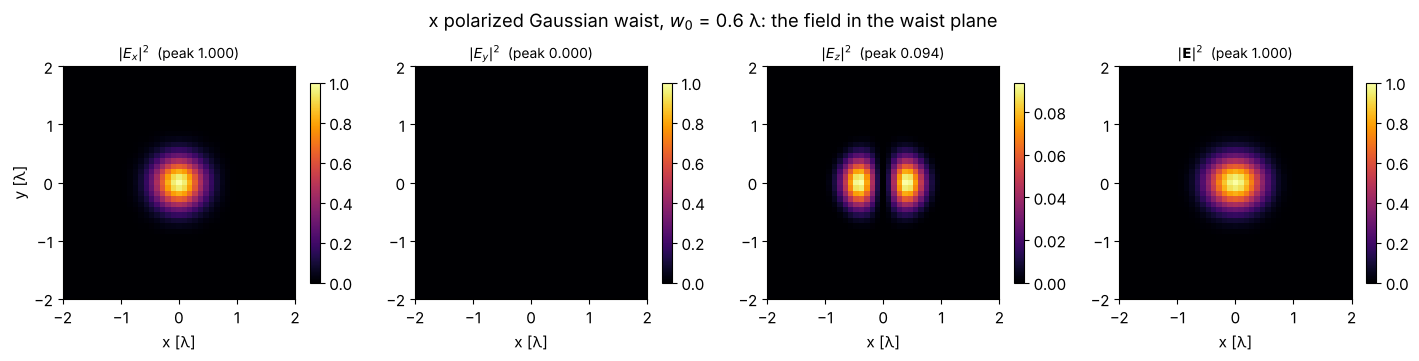

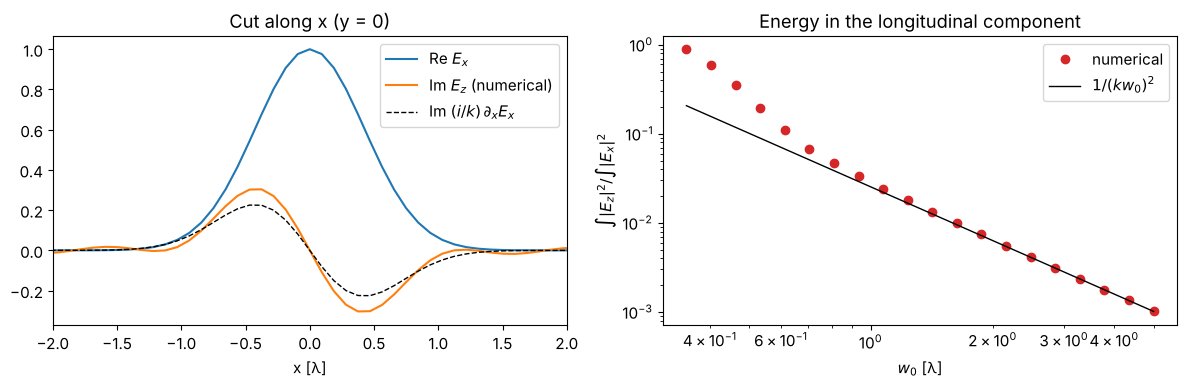

In [3]:
x, y, X, Y = grid(24.0, 256)
w0 = 0.6
E_x = np.exp(-(X**2 + Y**2)/w0**2)
E, _, _ = vectorial_rayleigh_sommerfeld_TF(np.stack([E_x, 0*E_x], -1), x, y, 0.0, wl)
show_components(E, x, y, "", extent_half=2,
                fig_title=f"x polarized Gaussian waist, $w_0$ = {w0} λ: the field in the waist plane");

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
row = 128
axes[0].plot(x, E[row, :, 0].real, label="Re $E_x$")
axes[0].plot(x, E[row, :, 2].imag, label="Im $E_z$ (numerical)")
axes[0].plot(x, (1j/k*(-2*X/w0**2)*E_x)[row].imag, "k--", lw=1, label="Im $(i/k)\\,\\partial_x E_x$")
axes[0].set_xlim(-2, 2); axes[0].set_xlabel("x [λ]"); axes[0].legend(); axes[0].set_title("Cut along x (y = 0)")

w0_vals = np.geomspace(0.35, 5, 20)
frac = []
for w in w0_vals:
    E_x = np.exp(-(X**2 + Y**2)/w**2)
    E_z = longitudinal_component(E_x, 0*E_x, x, y, wl)
    frac.append(np.sum(np.abs(E_z)**2)/np.sum(np.abs(E_x)**2))
axes[1].loglog(w0_vals, frac, "o", color="C3", label="numerical")
axes[1].loglog(w0_vals, 1/(k*w0_vals)**2, "k-", lw=1, label="$1/(k w_0)^2$")
axes[1].set_xlabel("$w_0$ [λ]"); axes[1].set_ylabel("$\\int|E_z|^2 / \\int|E_x|^2$")
axes[1].legend(); axes[1].set_title("Energy in the longitudinal component")
fig.tight_layout()

The paraxial estimate fails for waists below about one wavelength: the
spectrum then contains plane waves at large angles and evanescent waves, for
which $|E_z| = |E_x|\,|k_x/k_z|$ exceeds $|E_x|$.

## 3. Vector beams: radial and azimuthal polarization

A radially polarized doughnut beam, $[E_x, E_y] = [x, y]\exp(-r^2/w_0^2)$,
has a zero of its transverse field on the axis, but its tilted plane waves
all have $E_z$ components of the same sign there: a strong longitudinal field
fills the doughnut. The azimuthally polarized beam $[-y, x]\exp(-r^2/w_0^2)$
is divergence free in every plane and has no $E_z$ at all. We propagate both
from their waist ($w_0 = 0.6\lambda$) with `vectorial_rayleigh_sommerfeld_TF()`.

Such a tight Gaussian waist contains evanescent waves. Propagating forwards,
they decay; propagating backwards ($z < 0$) they would grow exponentially,
so we keep only the propagating part of the spectrum, $|\mathbf{k}_\perp| < k$.
This is the field a lens could actually produce.

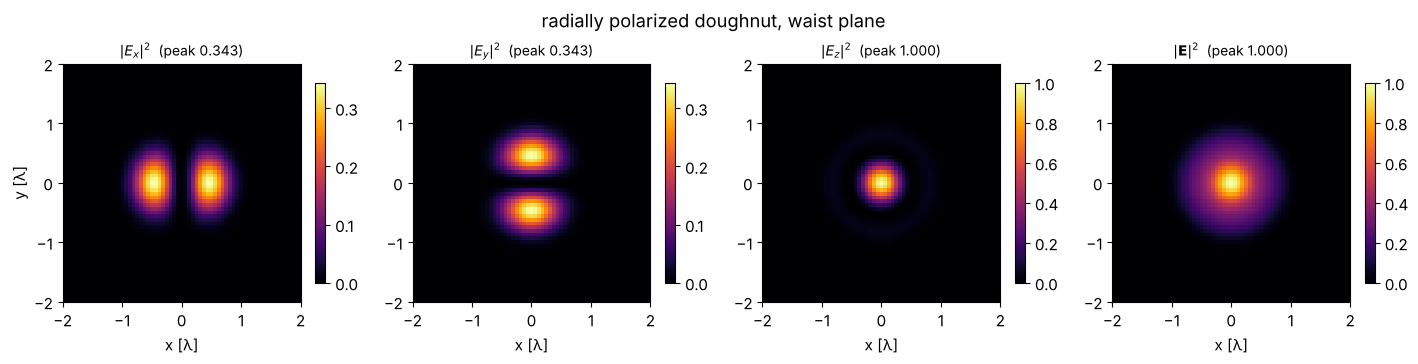

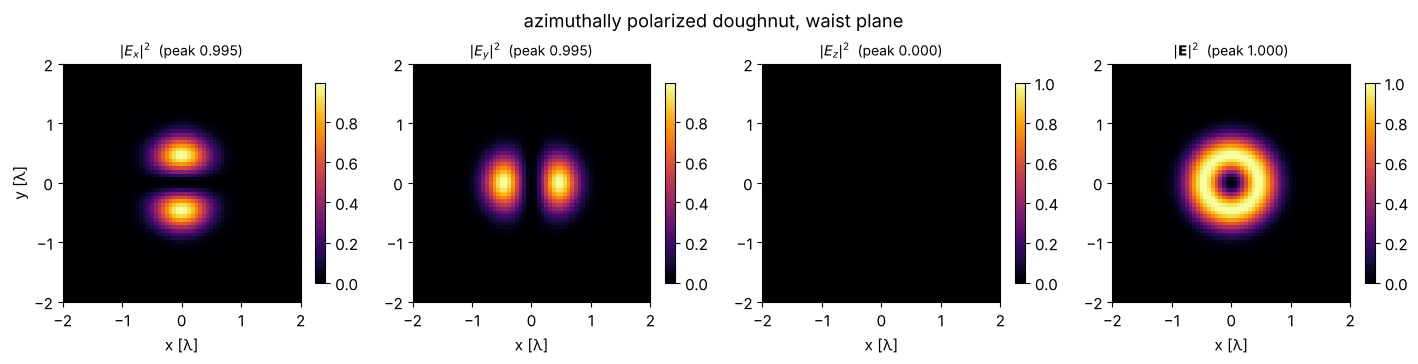

In [4]:
x, y, X, Y = grid(16.0, 256)
w0 = 0.6
G = np.exp(-(X**2 + Y**2)/w0**2)
K_x, K_y = freq_grid(x, y, wavenumbers=True, normal_order=True)
propagating = K_x**2 + K_y**2 < k**2
lowpass = lambda f: inv_FT(FT(f)*propagating)
radial = np.stack([lowpass(X*G), lowpass(Y*G)], -1)
azimuthal = np.stack([lowpass(-Y*G), lowpass(X*G)], -1)

for field, name in ((radial, "radially"), (azimuthal, "azimuthally")):
    E, _, _ = vectorial_rayleigh_sommerfeld_TF(field, x, y, 0.0, wl)
    show_components(E, x, y, "", extent_half=2, fig_title=f"{name} polarized doughnut, waist plane");

Propagating from the waist plane to $z = 4\lambda$ shows how the
longitudinal on-axis field of the radial beam spreads out; the transverse
doughnut keeps its zero on the axis. (We only propagate forwards: going
backwards, $z < 0$, even rounding errors in the evanescent part of the
spectrum grow like $\exp(|k_z||z|)$. For this real waist field
$|\mathbf{E}(-z)| = |\mathbf{E}(z)|$ anyway.)

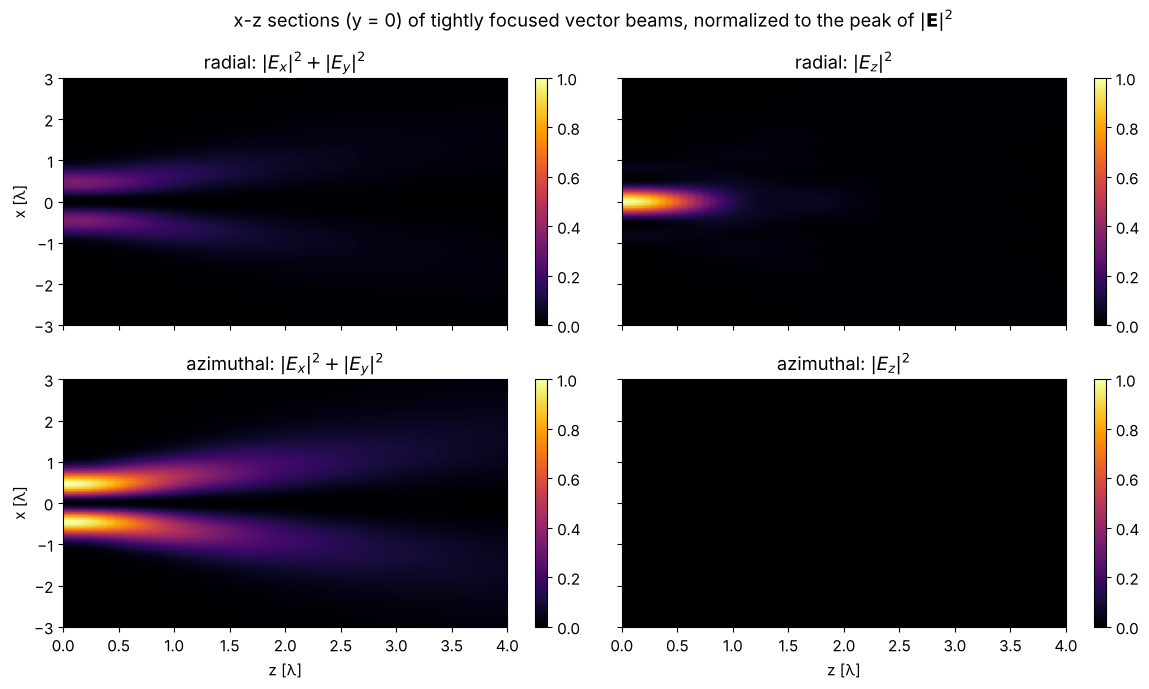

In [5]:
z_vals = np.linspace(0, 4, 61)
row = 128
xz = {"radial": [], "azimuthal": []}
for z in z_vals:
    for field, name in ((radial, "radial"), (azimuthal, "azimuthal")):
        E, _, _ = vectorial_rayleigh_sommerfeld_TF(field, x, y, z, wl)
        xz[name].append([np.abs(E[row, :, 0])**2 + np.abs(E[row, :, 1])**2, np.abs(E[row, :, 2])**2])
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for i, name in enumerate(("radial", "azimuthal")):
    data = np.array(xz[name])
    m = data.sum(axis=1).max()
    for j, label in enumerate(("$|E_x|^2 + |E_y|^2$", "$|E_z|^2$")):
        im = axes[i, j].imshow(data[:, j].T/m, extent=[z_vals[0], z_vals[-1], x[0], x[-1]],
                               aspect="auto", cmap="inferno", vmin=0, vmax=1)
        axes[i, j].set_title(f"{name}: {label}")
        axes[i, j].set_ylim(-3, 3)
        fig.colorbar(im, ax=axes[i, j])
for ax in axes[1]:
    ax.set_xlabel("z [λ]")
for ax in axes[:, 0]:
    ax.set_ylabel("x [λ]")
fig.suptitle("x-z sections (y = 0) of tightly focused vector beams, normalized to the peak of $|\\mathbf{E}|^2$")
fig.tight_layout()

## 4. Any scalar propagator, vectorized: `propagate_vectorial()`

`propagate_vectorial()` takes a scalar propagator for the transverse
components and adds $E_z$. With `rayleigh_sommerfeld_I_TF()` (the default
inside `vectorial_rayleigh_sommerfeld_TF()`) the result is exact; with
`fresnel_TF()` it is paraxial. The error of the Fresnel version compared to
the exact one, after $z = 20\lambda$, shrinks with the waist size like the
phase error of the Fresnel approximation, $k z\,\theta^4/8$ with the
divergence angle $\theta \sim 1/(k w_0)$, i.e. like $w_0^{-4}$:

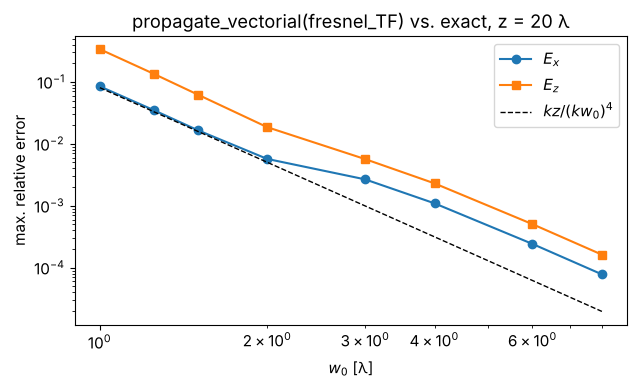

In [6]:
x, y, X, Y = grid(80.0, 512)
z = 20.0
w0_vals = np.array([1.0, 1.25, 1.5, 2, 3, 4, 6, 8])
errors = {i: [] for i in range(3)}
for w in w0_vals:
    E_x = np.exp(-(X**2 + Y**2)/w**2)
    field = np.stack([E_x, 0*E_x], -1)
    E_exact, _, _ = vectorial_rayleigh_sommerfeld_TF(field, x, y, z, wl)
    E_fr, _, _ = propagate_vectorial(fresnel_TF, field, x, y, z, wl)
    for i in (0, 2):
        errors[i].append(np.abs(E_fr[:, :, i] - E_exact[:, :, i]).max()/np.abs(E_exact[:, :, i]).max())
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(w0_vals, errors[0], "o-", label="$E_x$")
ax.loglog(w0_vals, errors[2], "s-", label="$E_z$")
ax.loglog(w0_vals, k*z/(k*w0_vals)**4, "k--", lw=1, label="$k z/(k w_0)^4$")
ax.set_xlabel("$w_0$ [λ]"); ax.set_ylabel("max. relative error")
ax.set_title("propagate_vectorial(fresnel_TF) vs. exact, z = 20 λ")
ax.legend(); fig.tight_layout()

For `fraunhofer()` (and `fresnel_rescaling()`) the output grid changes and
$E_z$ follows from the transversality of the far field,
$\mathbf{E}\cdot\mathbf{r} = 0$. Here the far field of a circular aperture of
radius $2\lambda$ illuminated with $x$ polarized light: the longitudinal
component appears in the direction of the polarization, while the
transverse components equal the scalar result.

Text(129.11284722222223, 0.5, 'angle y/z [°]')

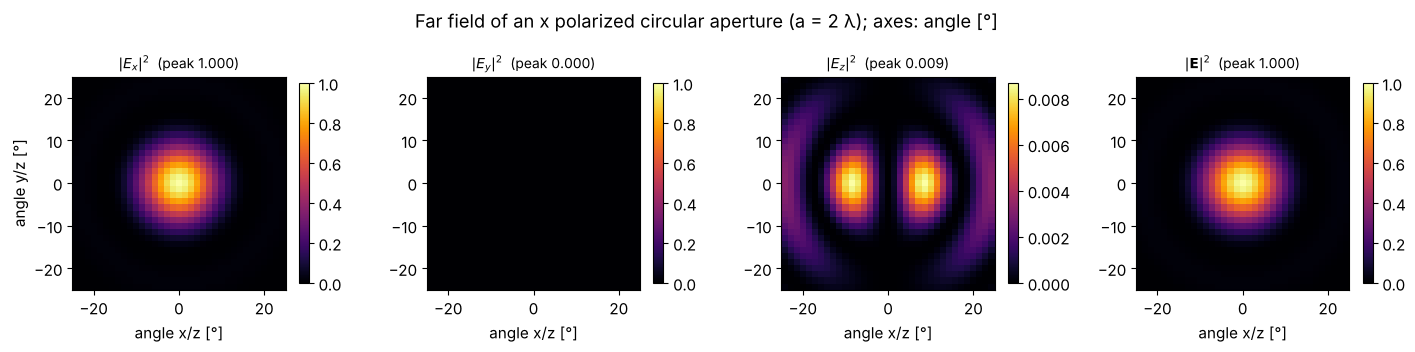

In [7]:
x, y, X, Y = grid(40.0, 256)
a = 2.0
aperture = np.where(X**2 + Y**2 < a**2, 1.0, 0.0)
z_ff = 2000.0
E_ff, x_ff, y_ff = propagate_vectorial(fraunhofer, np.stack([aperture, 0*aperture], -1), x, y, z_ff, wl)
fig = show_components(E_ff, np.degrees(x_ff/z_ff), np.degrees(y_ff/z_ff), "",
                      fig_title="Far field of an x polarized circular aperture (a = 2 λ); axes: angle [°]")
for ax in fig.axes:
    if ax.get_xlabel():
        ax.set_xlabel("angle x/z [°]"); ax.set_xlim(-25, 25); ax.set_ylim(-25, 25)
fig.axes[0].set_ylabel("angle y/z [°]")

## 5. Padding vector fields

FFT based propagation is cyclic. `propagate_padded()` now accepts vector
fields; the vectorial propagator computes $E_z$ inside the padded window.
A square aperture ($6\lambda$, $x$ polarized) whose spectrum is limited to
$|\mathbf{k}_\perp| < 0.4k$ (as if it were imaged by a lens with NA 0.4) is
propagated by $z = 30\lambda$ in a $20\lambda$ window. The light diffracted at
the largest angles reaches $|x| \approx 3 + 30\tan(23.6°) \approx 16\lambda$
and wraps around without padding. Note that $E_z$ lives where the light
travels obliquely, i.e. off axis in the $x$ direction.

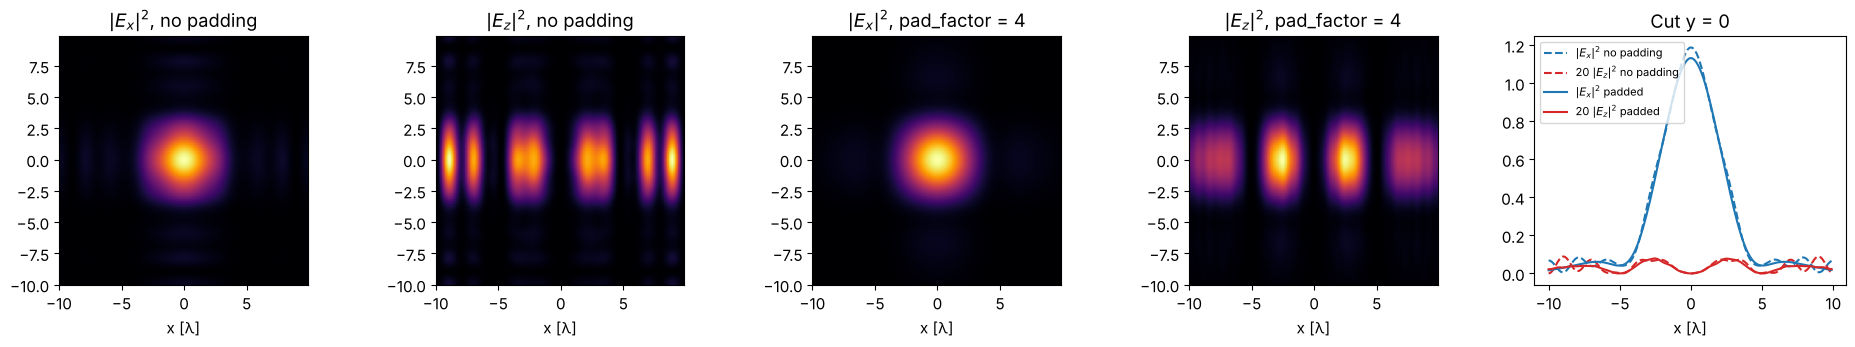

In [8]:
x, y, X, Y = grid(20.0, 160)
K_x, K_y = freq_grid(x, y, wavenumbers=True, normal_order=True)
sq = np.where((np.abs(X) < 3) & (np.abs(Y) < 3), 1.0, 0.0)
sq = inv_FT(FT(sq)*(K_x**2 + K_y**2 < (0.4*k)**2))
field = np.stack([sq, 0*sq], -1)
z = 30.0
E_cyc, _, _ = vectorial_rayleigh_sommerfeld_TF(field, x, y, z, wl)
E_pad, _, _ = propagate_padded(vectorial_rayleigh_sommerfeld_TF, field, x, y, z, wl, pad_factor=4)
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
ext = [x[0], x[-1], y[0], y[-1]]
for ax, E, c, name in ((axes[0], E_cyc, 0, "$|E_x|^2$, no padding"), (axes[1], E_cyc, 2, "$|E_z|^2$, no padding"),
                       (axes[2], E_pad, 0, "$|E_x|^2$, pad_factor = 4"), (axes[3], E_pad, 2, "$|E_z|^2$, pad_factor = 4")):
    ax.imshow(np.abs(E[:, :, c])**2, extent=ext, cmap="inferno"); ax.set_title(name); ax.set_xlabel("x [λ]")
row = len(y)//2
for E, name, ls in ((E_cyc, "no padding", "--"), (E_pad, "padded", "-")):
    axes[4].plot(x, np.abs(E[row, :, 0])**2, ls, color="C0", label=f"$|E_x|^2$ {name}")
    axes[4].plot(x, 20*np.abs(E[row, :, 2])**2, ls, color="C3", label=f"20 $|E_z|^2$ {name}")
axes[4].set_xlabel("x [λ]"); axes[4].legend(fontsize=8); axes[4].set_title("Cut y = 0")
fig.tight_layout()

## 6. High NA focusing: Mansuripur's method

A lens that obeys the sine condition (an aplanatic lens) maps a point
$(\rho, \varphi)$ of its pupil, $\rho = f\sin\theta$, to a plane wave travelling
in the direction $\boldsymbol{\sigma} = (\sin\theta\cos\varphi, \sin\theta\sin\varphi, \cos\theta)$.
The polarization of each ray is rotated with the ray about the axis
$\hat{z}\times\boldsymbol{\sigma}$: its s component (perpendicular to the meridional
plane) is kept, its p component tilts (`aplanatic_rotation()`).
Energy conservation between the pupil and the converging spherical wave adds
the apodization $1/\sqrt{\cos\theta}$ on the $\sigma$ grid. This is Mansuripur's
FFT formulation of the Richards-Wolf theory.

`vectorial_mansuripur(field, ...)` interprets the angular spectrum of
`field` as the pupil. So for a pupil $P(\sigma_x, \sigma_y)$ we pass
`inv_FT(P)` (the paraxial focal field) and get the vectorial focus at the
distance $z$ from the focal plane.

First, the columns of the rotation matrix for an $x$ polarized pupil: the
polarization lines in the pupil after the lens (projected to $x$-$y$) and the
longitudinal part, which is largest along the $x$ axis.

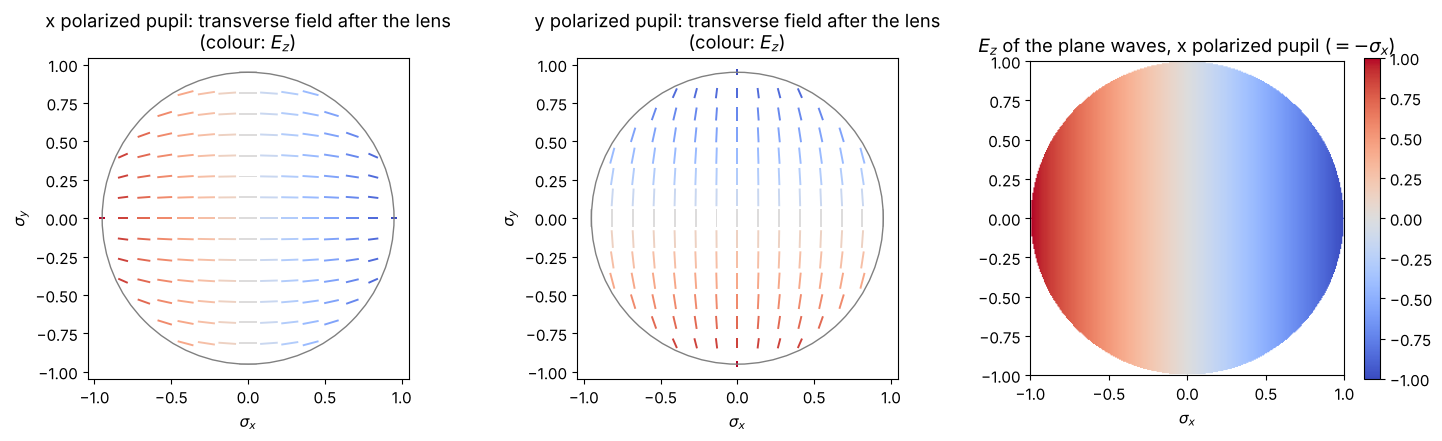

In [9]:
s = np.linspace(-0.95, 0.95, 15)
SX, SY = np.meshgrid(s, s)
inside = SX**2 + SY**2 <= 0.95**2
R = aplanatic_rotation(np.where(inside, SX, 0), np.where(inside, SY, 0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, name in ((axes[0], 0, "x"), (axes[1], 1, "y")):
    ax.quiver(SX[inside], SY[inside], R[0, col][inside], R[1, col][inside], R[2, col][inside],
              cmap="coolwarm", pivot="middle", headwidth=1, headlength=0, headaxislength=0, width=0.006, scale=18)
    ax.add_patch(plt.Circle((0, 0), 0.95, fill=False, color="gray"))
    ax.set_aspect("equal"); ax.set_xlabel("$\\sigma_x$"); ax.set_ylabel("$\\sigma_y$")
    ax.set_title(f"{name} polarized pupil: transverse field after the lens\n(colour: $E_z$)")
sg = np.linspace(-1, 1, 301)
SGX, SGY = np.meshgrid(sg, sg)
Rg = aplanatic_rotation(np.clip(SGX, -1, 1)*(SGX**2 + SGY**2 <= 1), SGY*(SGX**2 + SGY**2 <= 1))
im = axes[2].imshow(np.where(SGX**2 + SGY**2 <= 1, Rg[2, 0], np.nan), extent=[-1, 1, -1, 1], cmap="coolwarm", vmin=-1, vmax=1)
axes[2].set_title("$E_z$ of the plane waves, x polarized pupil ($= -\\sigma_x$)")
axes[2].set_xlabel("$\\sigma_x$"); fig.colorbar(im, ax=axes[2])
fig.tight_layout()

### Focal spots for NA 0.5, 0.8 and 0.95

With increasing NA, the $|E_z|^2$ lobes grow and the total focal spot of
linearly polarized light becomes elongated along the polarization
direction. The scalar theory (Airy pattern) knows nothing of this.

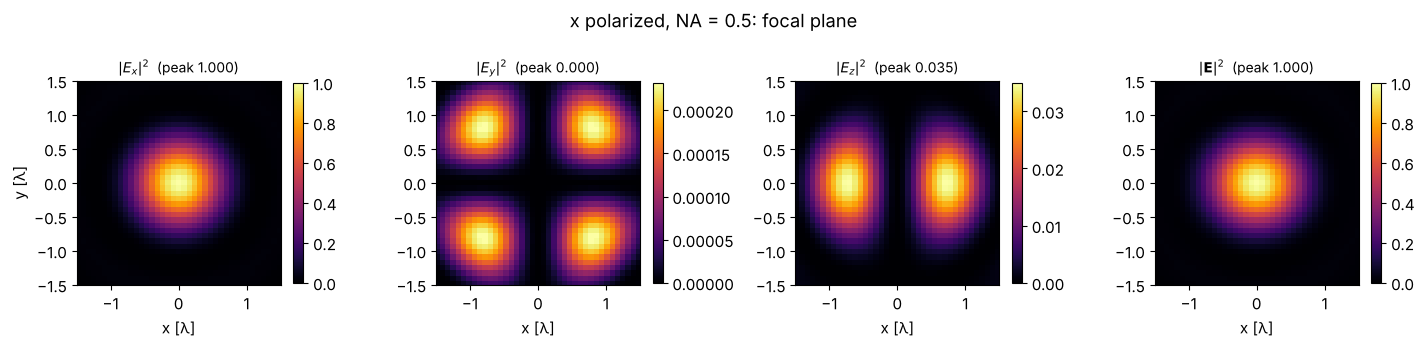

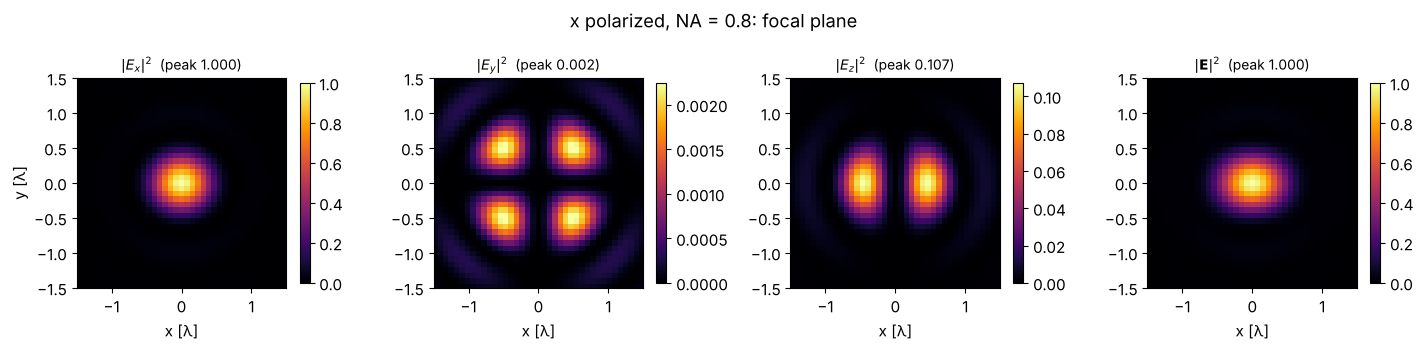

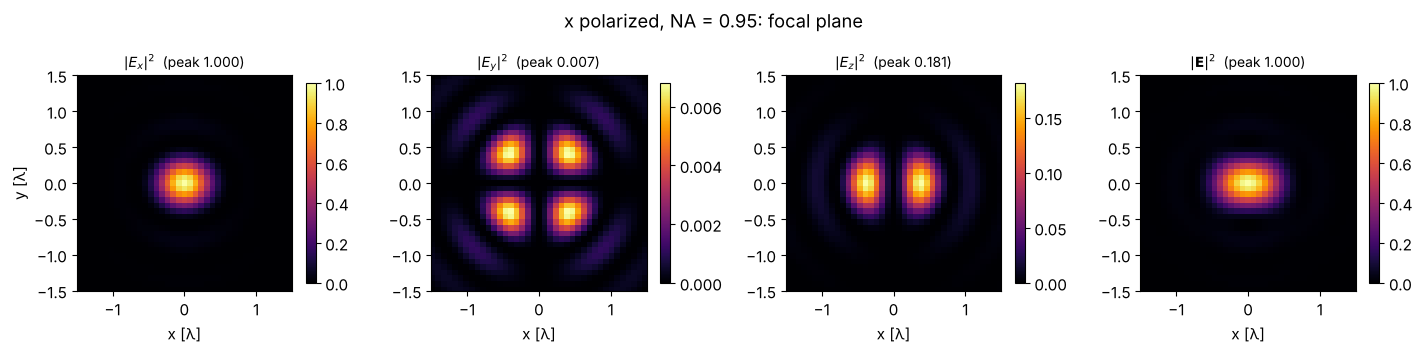

In [10]:
L, N = 40.0, 512
x, y, X, Y = grid(L, N)
K_x, K_y = freq_grid(x, y, wavenumbers=True, normal_order=True)
S = np.hypot(K_x, K_y)/k
c = N//2

def focus(NA, pol=(1, 0), z=0.0, pupil=None, n=1.0):
    """Vectorial focus of a uniformly filled pupil (or pupil(S) given) with Jones vector pol."""
    P = np.where(S < NA/n, 1.0 if pupil is None else pupil(S), 0.0)
    if callable(pol):
        p_x, p_y = pol(K_x/k, K_y/k)
    else:
        p_x, p_y = pol
    field = np.stack([inv_FT(p_x*P), inv_FT(p_y*P)], -1)
    return vectorial_mansuripur(field, x, y, z, wl, n=n)[0]

for NA in (0.5, 0.8, 0.95):
    E = focus(NA)
    show_components(E, x, y, "", extent_half=1.5, fig_title=f"x polarized, NA = {NA}: focal plane");

Cuts along $x$ (parallel to the polarization) and $y$, compared with the
scalar Airy pattern $\left[2J_1(v)/v\right]^2$, $v = k\,\mathrm{NA}\,r$:

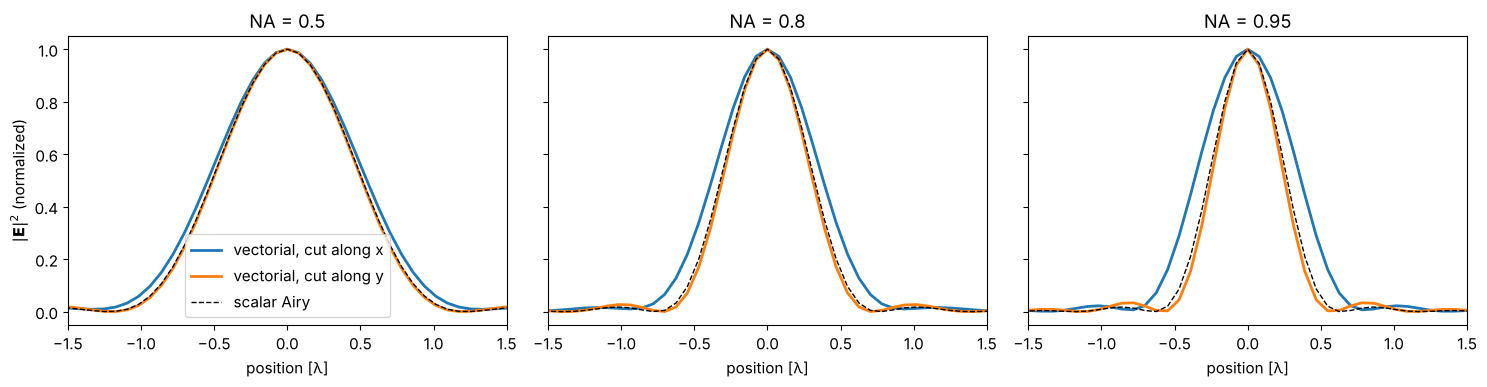

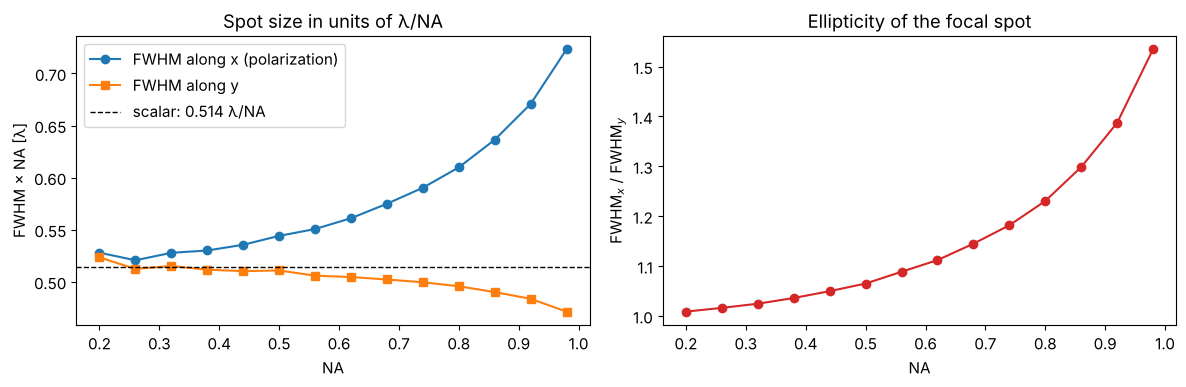

In [11]:
def fwhm(xs, I):
    I = I/I.max()
    i0 = np.argmax(I)
    def side(rng):
        for i in rng:
            if I[i] < 0.5:
                j = i - rng.step
                return xs[i] + (0.5 - I[i])*(xs[j] - xs[i])/(I[j] - I[i])
    return side(range(i0, len(I), 1)) - side(range(i0, -1, -1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
xs = x
for ax, NA in zip(axes, (0.5, 0.8, 0.95)):
    E = focus(NA)
    I = sum(components(E)); I /= I.max()
    ax.plot(xs, I[c, :], lw=2, label="vectorial, cut along x")
    ax.plot(xs, I[:, c], lw=2, label="vectorial, cut along y")
    v = k*NA*np.abs(xs) + 1e-12
    ax.plot(xs, (2*j1(v)/v)**2, "k--", lw=1, label="scalar Airy")
    ax.set_xlim(-1.5, 1.5); ax.set_title(f"NA = {NA}"); ax.set_xlabel("position [λ]")
axes[0].set_ylabel("$|\\mathbf{E}|^2$ (normalized)"); axes[0].legend()
fig.tight_layout()

NA_vals = np.linspace(0.2, 0.98, 14)
fw_x, fw_y = [], []
for NA in NA_vals:
    I = sum(components(focus(NA)))
    fw_x.append(fwhm(x, I[c, :])); fw_y.append(fwhm(y, I[:, c]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(NA_vals, np.array(fw_x)*NA_vals, "o-", label="FWHM along x (polarization)")
axes[0].plot(NA_vals, np.array(fw_y)*NA_vals, "s-", label="FWHM along y")
axes[0].axhline(0.5145, color="k", ls="--", lw=1, label="scalar: 0.514 λ/NA")
axes[0].set_xlabel("NA"); axes[0].set_ylabel("FWHM × NA [λ]"); axes[0].legend()
axes[0].set_title("Spot size in units of λ/NA")
axes[1].plot(NA_vals, np.array(fw_x)/np.array(fw_y), "o-", color="C3")
axes[1].set_xlabel("NA"); axes[1].set_ylabel("FWHM$_x$ / FWHM$_y$"); axes[1].set_title("Ellipticity of the focal spot")
fig.tight_layout()

The FWHM is evaluated by linear interpolation on a grid with spacing
$0.078\lambda$, which is good to about 1 %.

### Check against the Richards-Wolf integrals

For an $x$ polarized, uniformly filled pupil Richards and Wolf give the focal
field as one-dimensional integrals over the aperture angle
$\theta \le \alpha = \arcsin\mathrm{NA}$:

$$ E_x \propto I_0 + I_2\cos 2\varphi,\quad E_y \propto I_2 \sin 2\varphi,\quad E_z \propto -2i I_1\cos\varphi, $$
$$ I_{0,2} = \int_0^\alpha \sqrt{\cos\theta}\,\sin\theta\,(1\pm\cos\theta)\,J_{0,2}(k\rho\sin\theta)\,e^{ikz\cos\theta}\,d\theta,\quad
   I_1 = \int_0^\alpha \sqrt{\cos\theta}\,\sin^2\theta\,J_1(k\rho\sin\theta)\,e^{ikz\cos\theta}\,d\theta. $$

We evaluate them with `scipy.integrate.quad` along the diagonal
$\varphi = 45°$ (where all three components are present) for NA 0.9.

z = 0.0: max deviation / peak = 3.3e-03
z = 0.5: max deviation / peak = 3.7e-03


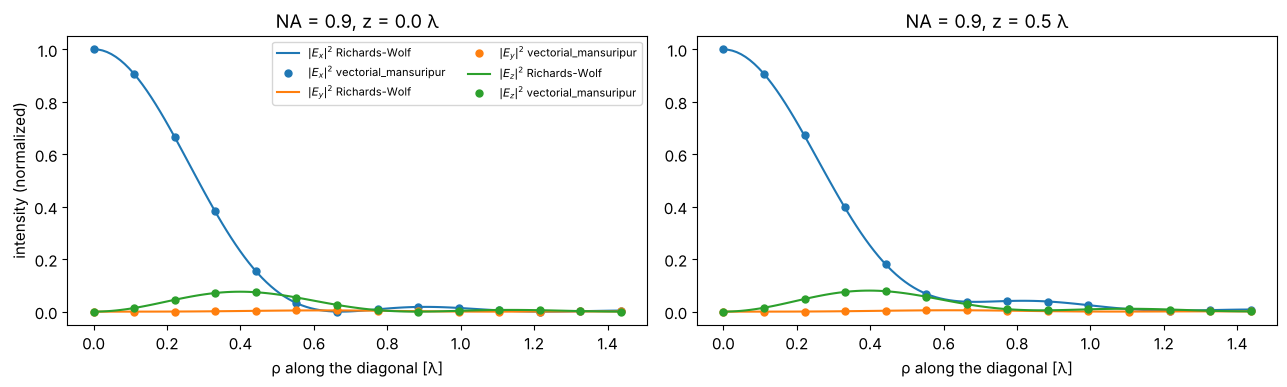

In [12]:
def richards_wolf(rho, phi, z, NA):
    def integral(f):
        g = lambda t: f(t)*np.sqrt(np.cos(t))*np.sin(t)*np.exp(1j*k*z*np.cos(t))
        kw = dict(a=0, b=np.arcsin(NA), limit=200)
        return quad(lambda t: g(t).real, **kw)[0] + 1j*quad(lambda t: g(t).imag, **kw)[0]
    I0 = integral(lambda t: (1 + np.cos(t))*jv(0, k*rho*np.sin(t)))
    I1 = integral(lambda t: np.sin(t)*jv(1, k*rho*np.sin(t)))
    I2 = integral(lambda t: (1 - np.cos(t))*jv(2, k*rho*np.sin(t)))
    return np.array([I0 + I2*np.cos(2*phi), I2*np.sin(2*phi), -2j*I1*np.cos(phi)])

NA = 0.9
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, z in zip(axes, (0.0, 0.5)):
    E = focus(NA, z=z)
    d = np.arange(0, 14)
    num = np.array([E[c + i, c + i] for i in d])
    rho = np.sqrt(2)*x[c + d]
    ref = np.array([richards_wolf(r, np.pi/4, z, NA) for r in rho])
    scale = np.vdot(ref.ravel(), num.ravel())/np.vdot(ref.ravel(), ref.ravel())
    rr = np.linspace(0, rho[-1], 120)
    ref_fine = np.array([richards_wolf(r, np.pi/4, z, NA) for r in rr])*scale
    m = np.sum(np.abs(num)**2, axis=1).max()
    for i, name in enumerate(("$|E_x|^2$", "$|E_y|^2$", "$|E_z|^2$")):
        ax.plot(rr, np.abs(ref_fine[:, i])**2/m, color=f"C{i}", lw=1.5, label=f"{name} Richards-Wolf")
        ax.plot(rho, np.abs(num[:, i])**2/m, "o", color=f"C{i}", ms=5, label=f"{name} vectorial_mansuripur")
    ax.set_xlabel("ρ along the diagonal [λ]"); ax.set_title(f"NA = {NA}, z = {z} λ")
    print(f"z = {z}: max deviation / peak = {np.abs(num - scale*ref).max()/np.abs(num).max():.1e}")
axes[0].legend(fontsize=8, ncol=2); axes[0].set_ylabel("intensity (normalized)")
fig.tight_layout()

The remaining deviation of a few $10^{-3}$ comes from sampling the hard pupil
edge on the $\sigma$ grid ($\Delta\sigma = \lambda/L = 0.025$). With a smooth pupil
the agreement is better than $10^{-4}$ (see `test/test_vectorial.py`).

### Pupil polarization: linear, circular, radial, azimuthal

The polarization in the pupil decides the shape of the focus. At NA 0.9:

- linear: elongated spot (see above),
- circular: round spot, but wider than the scalar one, $E_z$ forms a ring,
- radial: the transverse field has a zero at the center, $E_z$ a strong peak
  there,
- azimuthal: no $E_z$ at all, a doughnut.

Radial polarization with an annular pupil gives a smaller spot than
any other polarization, because then the longitudinal component dominates
(Quabis et al., Opt. Commun. 179, 1 (2000); Dorn, Quabis and Leuchs,
Phys. Rev. Lett. 91, 233901 (2003)).

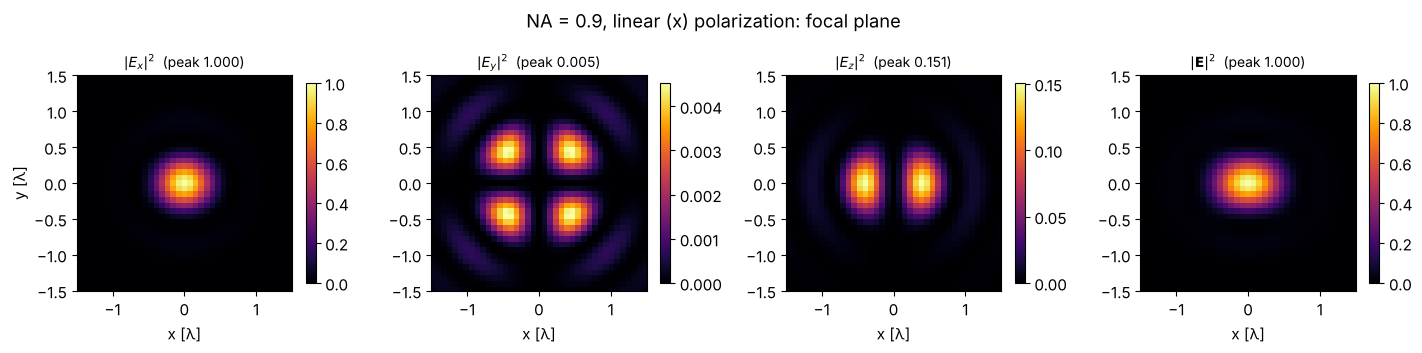

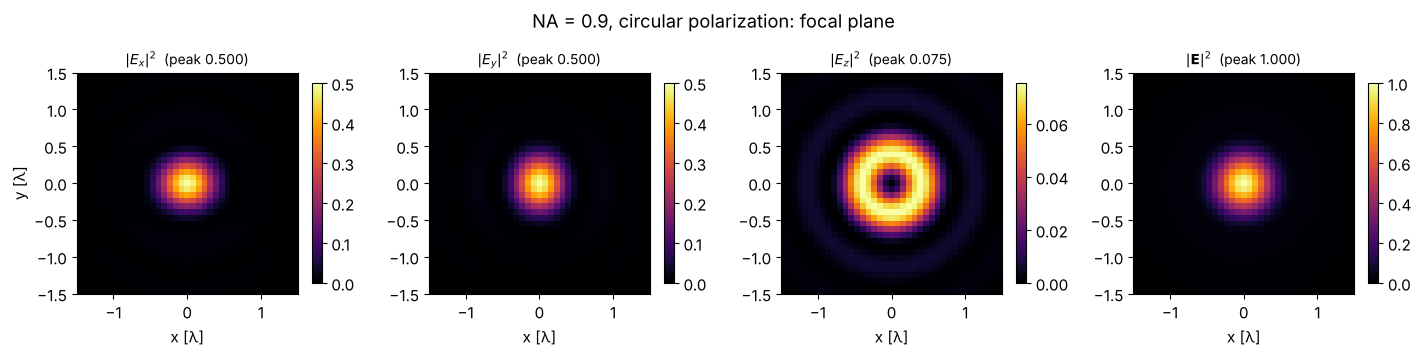

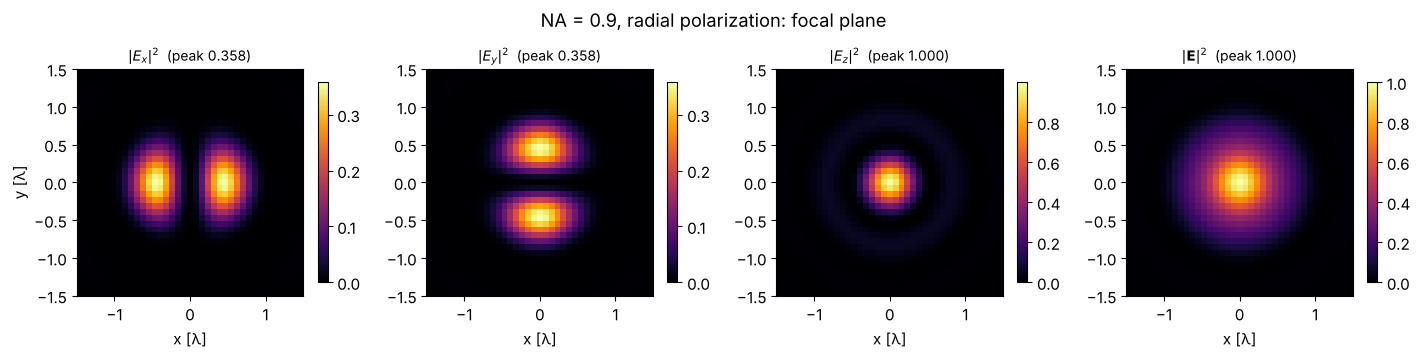

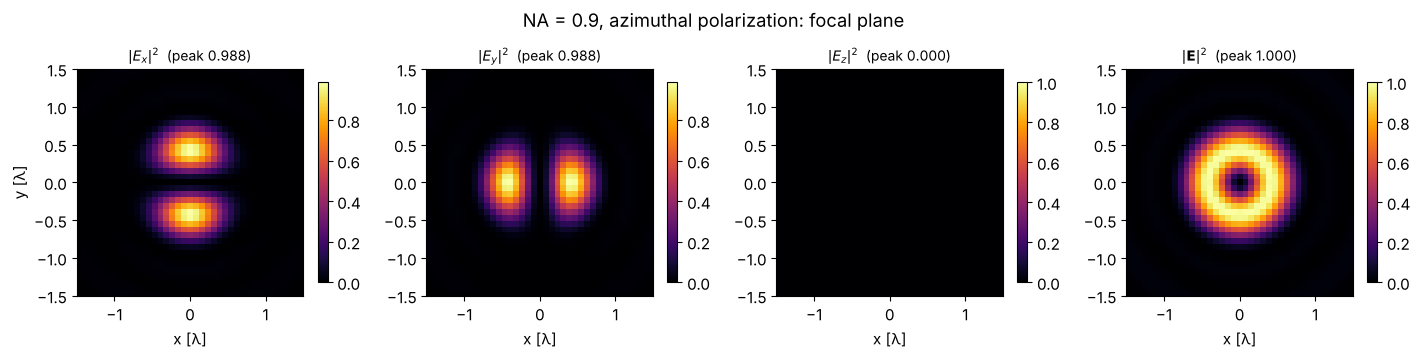

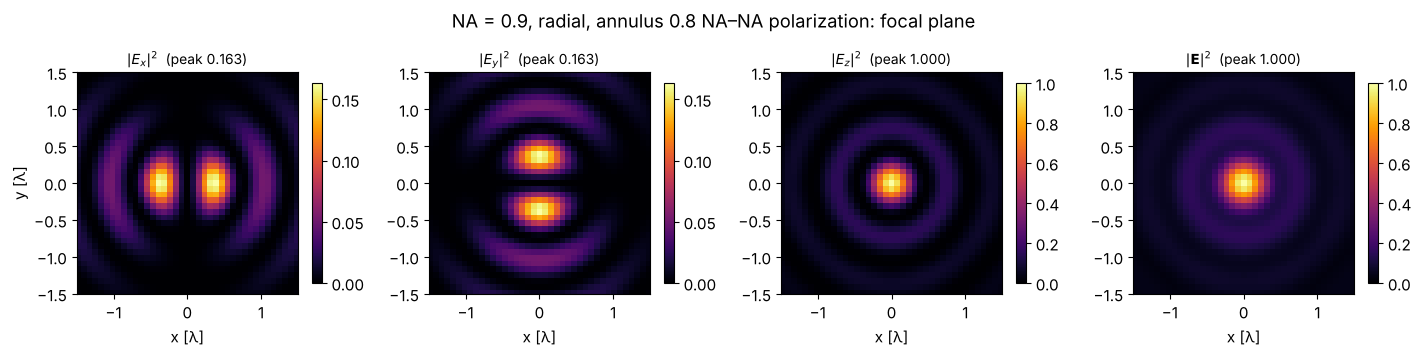

In [13]:
def radial_pol(sx, sy):
    phi = np.arctan2(sy, sx)
    return np.cos(phi), np.sin(phi)

def azimuthal_pol(sx, sy):
    phi = np.arctan2(sy, sx)
    return -np.sin(phi), np.cos(phi)

NA = 0.9
cases = [("linear (x)", (1, 0), None), ("circular", (1/np.sqrt(2), 1j/np.sqrt(2)), None),
         ("radial", radial_pol, None), ("azimuthal", azimuthal_pol, None),
         ("radial, annulus 0.8 NA–NA", radial_pol, lambda s: (s > 0.8*NA).astype(float))]
results = {}
for name, pol, pupil in cases:
    E = focus(NA, pol=pol, pupil=pupil)
    results[name] = E
    show_components(E, x, y, "", extent_half=1.5, fig_title=f"NA = {NA}, {name} polarization: focal plane");

linear (x)                   spot area 0.311 λ²
circular                     spot area 0.275 λ²
radial                       spot area 0.421 λ²
radial, annulus 0.8 NA–NA    spot area 0.226 λ²
scalar Airy                  spot area 0.257 λ²


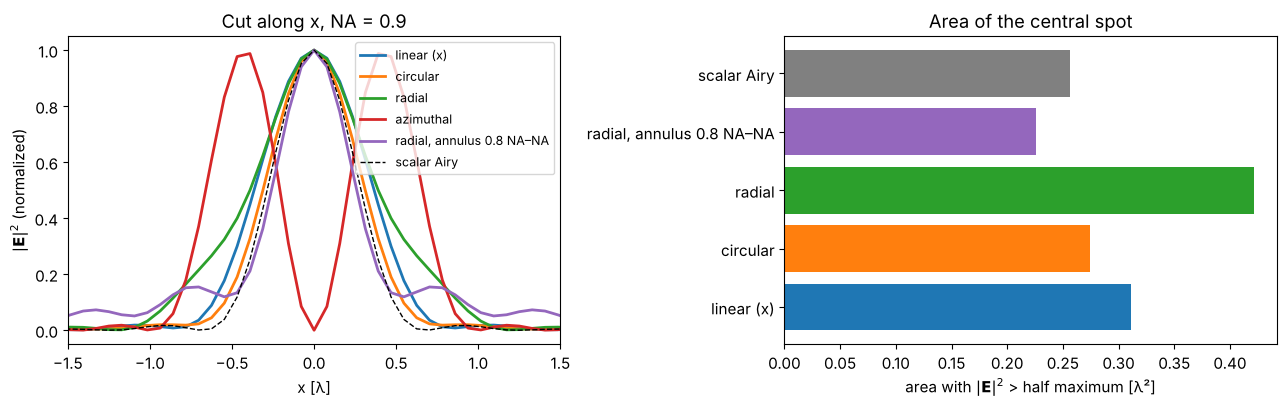

In [14]:
dA = (x[1] - x[0])**2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = list(results)
areas = []
for i, name in enumerate(names):
    I = sum(components(results[name])); I /= I.max()
    axes[0].plot(x, I[c, :], lw=2, label=name)
    areas.append(np.sum(I > 0.5)*dA)
v = k*NA*np.abs(x) + 1e-12
axes[0].plot(x, (2*j1(v)/v)**2, "k--", lw=1, label="scalar Airy")
axes[0].set_xlim(-1.5, 1.5); axes[0].set_xlabel("x [λ]"); axes[0].set_ylabel("$|\\mathbf{E}|^2$ (normalized)")
axes[0].legend(fontsize=9); axes[0].set_title(f"Cut along x, NA = {NA}")
airy_area = np.pi*(0.5145/NA/2)**2
spots = [i for i, name in enumerate(names) if name != "azimuthal"]   # the doughnut has no central spot
axes[1].barh([names[i] for i in spots] + ["scalar Airy"], [areas[i] for i in spots] + [airy_area],
             color=[f"C{i}" for i in spots] + ["gray"])
axes[1].set_xlabel("area with $|\\mathbf{E}|^2$ > half maximum [λ²]")
axes[1].set_title("Area of the central spot")
for i in spots:
    print(f"{names[i]:28s} spot area {areas[i]:.3f} λ²")
print(f"{'scalar Airy':28s} spot area {airy_area:.3f} λ²")
fig.tight_layout()

### Through focus

`vectorial_mansuripur()` takes the distance $z$ from the focal plane, so a
through focus scan is just a loop. $x$-$z$ and $y$-$z$ sections of the total
energy density for an $x$ polarized pupil at NA 0.9: the axial extent is
about $2\lambda/\mathrm{NA}^2$-ish, the lateral one differs between $x$ and $y$.

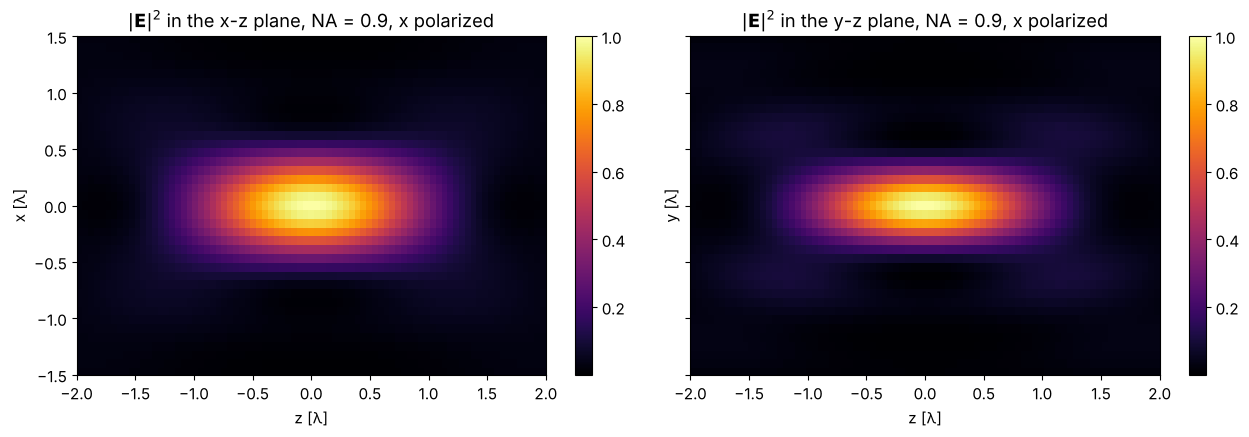

In [15]:
NA = 0.9
z_vals = np.linspace(-2, 2, 81)
xz, yz = [], []
for z in z_vals:
    I = sum(components(focus(NA, z=z)))
    xz.append(I[c, :]); yz.append(I[:, c])
xz, yz = np.array(xz), np.array(yz)
m = max(xz.max(), yz.max())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, data, name in ((axes[0], xz, "x"), (axes[1], yz, "y")):
    im = ax.imshow(data.T/m, extent=[z_vals[0], z_vals[-1], x[0], x[-1]], aspect="auto", cmap="inferno")
    ax.set_ylim(-1.5, 1.5); ax.set_xlabel("z [λ]"); ax.set_ylabel(f"{name} [λ]")
    ax.set_title(f"$|\\mathbf{{E}}|^2$ in the {name}-z plane, NA = {NA}, x polarized")
    fig.colorbar(im, ax=ax)
fig.tight_layout()

### Energy conservation and transversality

The $1/\sqrt{\sigma_z}$ weight makes the power flowing through every plane
$z = \mathrm{const}$ equal to the power of the input field, and each plane
wave is transverse, so $\mathbf{k}\cdot\tilde{\mathbf{E}} = 0$:

In [16]:
sz = np.sqrt(np.clip(1 - S**2, 0, None))
for NA in (0.5, 0.9, 0.98):
    P = np.where(S < NA, 1.0, 0.0)
    field = np.stack([inv_FT(P), inv_FT(0*P)], -1)
    p_in = np.sum(np.abs(FT(field[:, :, 0]))**2)
    for z in (0.0, 1.5):
        E = vectorial_mansuripur(field, x, y, z, wl)[0]
        Ek = [FT(E[:, :, i]) for i in range(3)]
        p_out = sum(np.sum(np.abs(Ek[i])**2*sz) for i in range(3))
        div = np.abs(K_x*Ek[0] + K_y*Ek[1] + k*sz*Ek[2]).max()/(k*np.abs(Ek[0]).max())
        print(f"NA {NA}, z = {z}: power out/in = {p_out/p_in:.12f}, max |k·E|/(k max|E|) = {div:.1e}")

NA 0.5, z = 0.0: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 1.4e-15
NA 0.5, z = 1.5: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 1.4e-15


NA 0.9, z = 0.0: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 1.4e-15
NA 0.9, z = 1.5: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 1.3e-15


NA 0.98, z = 0.0: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 1.1e-15
NA 0.98, z = 1.5: power out/in = 1.000000000000, max |k·E|/(k max|E|) = 9.2e-16


## Summary

- `longitudinal_component()` and `vectorial_rayleigh_sommerfeld_TF()` turn
  the transverse field in a plane into the full, divergence free vector field
  in any other plane, exactly.
- `propagate_vectorial()` does the same for every scalar propagator, so
  Fresnel and Fraunhofer computations get their $E_z$ too; `propagate_padded()`
  pads vector fields.
- `vectorial_mansuripur()` (formerly `vectorial_fresnel()`, which is now a
  deprecated alias) computes the focus of an aplanatic lens and agrees with
  the Richards-Wolf integrals. Linearly polarized foci are elongated along
  the polarization; radial polarization with an annular pupil gives the
  smallest spot.